In [1]:
import sys, time
from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next(c for c in [_p, *_p.parents] if (c / 'C' / 'evoca.h').is_file())
sys.path.insert(0, str(ROOT / 'python'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import evoca_explore as ee
from evoca_py import import_run

WS = 'Resource-driving'
NB_T0 = time.time()
print('repo root:', ROOT)

repo root: /private/tmp/evoca_food-cap-standard


# Resource-driving: lab notebook

**Question.** Does evolvability peak at *intermediate* resource driving (an inverted U), and is the true
control axis the gradient steepness `food_inc / tax` (with the per-capita dissipation throughput
Phi as the physical x-axis) rather than `food_inc` alone?

Chronological lab notebook (newest section at the bottom). Finished campaign write-ups live in
[`digests/viability-brackets.ipynb`](digests/viability-brackets.ipynb) (R1, draft digest) and
[`digests/resource-driving-inverted-U.ipynb`](digests/resource-driving-inverted-U.ipynb) (skeleton;
no sweep run yet). Raw scan data: [`Scans/2026-10-23_R1_mscale_bracket_standard/`](Scans/2026-10-23_R1_mscale_bracket_standard/) (standard-model rescan of R1, used in the main thread), [`Scans/2026-05-18_R1_mscale_bracket/`](Scans/2026-05-18_R1_mscale_bracket/notes.md) (R1 as recorded, legacy rule), [`Scans/2026-10-15_food_cap_impact/`](Scans/2026-10-15_food_cap_impact/notes.md) (both-rules comparison).
Open questions and next directions are in `ISSUES.md` (shown next).

**Running the examples interactively.** After each example run there is a code cell of commented-out lines that open the same configuration in the interactive SDL window (`run_with_controls`, from `python/controls.py`). Uncomment and run it to watch the simulation; it is commented out so that *Run All* never blocks on a window. Only one EvoCA lattice exists at a time, so this replaces any simulation still alive in the kernel.

**Eating rule.** Everything above the final section uses the **standard model**: the capped mouthful (`food_cap=1`, the A9 fix), under which a cell never eats more food than its site holds. The legacy uncapped rule (`food_cap=0`) let `m_scale x score > 25` overdraw the site, drive `F` negative and drain the next eater's private food. It is unphysical and not part of the model. Every R1 row has `m_scale` >= 2.5, where the cap binds, so the main thread reads R1 from its 2026-10-23 standard-model rescan (same driver, configs and protocol, today's code, `food_cap=1`), and every example run is capped. R1's recorded (legacy) findings, set against the rescan, the legacy half of the `food_cap_impact` comparison and the example triple under the legacy rule are in the final section, "Legacy rule (`food_cap=0`)".

*Snapshot of `ISSUES.md` as of the last execution of this notebook. `ISSUES.md` is the single source of
truth; edit it there, not here.*

In [2]:
display(Markdown((ROOT / 'Research' / WS / 'ISSUES.md').read_text()))

# Resource-driving: issues and directions
_Updated 2026-10-23_

## Decisions needed (N)
- **RES-D1** (resolved 2026-10-15): N authorized the Tier-2 merge; `resource-driving` (C1 `food_per`) is on `main` after bit-for-bit parity at `food_per=1`. Record: `Docs/Archive/Oct2026/01-branch-review.md`, Tier-2 section.
- **RES-D2**: Evolution arms for the RES-N1 campaign — options: (a) LUT-only (`mu_egene = mu_egenome = 0`), where `A_new` is well posed; (b) joint LUT + egene as in R1 and the checkpoint's two "exception" hypotheses, where `A_new` is not well posed (RES-Q3) and only the fixed-space `eg_excess` / `dyn_excess` and eff-activity are interpretable; (c) both as separate arms. Recommendation: (c), with (a) as the primary inverted-U figure. Blocks: RES-N1 design freeze.

## Open questions
- **RES-Q1**: Is the high-resource flank a drift regime (raw diversity high, excess near zero), as checkpoint section B predicts? R1 never sampled `food_inc` above 0.018, so the high half of the inverted U is untested at campaign scale. The 2026-10-15 pilot (1 seed, `tax` 0.035, LUT-only, N=128, 3000 steps; notebook pilot section) shows `A_new` rising, peaking in the interior and collapsing at `food_inc/tax` about 2.9 while raw distinct-genome count saturates — suggestive only, and confounded by occupancy (below ratio 1 more cells means more genomes; judge excess per capita or against a population-matched baseline). 2026-10-23: re-run under the standard model (`food_cap=1`), the pilot keeps the shape: `A_new` peaks at ratio 0.6 (1689) and is 7 at ratio 2.86, while the raw count saturates at 15851. Source: `Docs/checkpoint 3 July 2026.md` section B; notebook pilot.
- **RES-Q2**: Does per-capita throughput Phi carry information beyond `food_inc/tax`? In the pilot, Phi sits at about `tax` whenever the population is food-limited and nothing overflows, and rises toward `food_inc` only on the overflow-dominated rich flank, so as an x-axis it is nearly degenerate across the viable interior. This follows from the L1 energy identity: at quasi-steady state Phi = max(`tax`, `food_inc`), and below ratio 1 the final alive density equals `food_inc/tax` (0.399, 0.600, 0.899 vs 0.4, 0.6, 0.9 in the 2026-10-23 standard-model pilot, ratios 0.4-0.9; ratio 0.3 oscillates), so the ratio is also the carrying occupancy. Test: Phi vs the ratio across `tax` levels in RES-N1; also try total throughput per cell and Phi restricted to cells with positive mouthful.
- **RES-Q3**: `A_new` (G1) is built on the LUT-hash Channon shadow, which models LUT bytes only, while the activity hash covers the full genome. Per the recorded `shadow-models-lut-only-mismatch` finding (and `Docs/EvoCA_research_directions.md` section 2), excess metrics are not well posed when egenes evolve. Is `A_new` interpretable in the joint LUT + egene arm? Needs either an egene-aware shadow for `A_new`, or restriction to LUT-only arms. Do not interpret `A_new` from R1-style joint runs.
- **RES-Q4**: Does the viability threshold and the productive peak collapse onto `food_inc/tax`? Weak hint in R1: 2026-10-23, in the standard-model rescan, ordering extinction by the ratio has AUC 0.894 vs 0.872 by `food_inc` alone (recorded legacy rows: 0.863 vs 0.839), and at `food_inc` 0.008 extinction is 0/6/23% at `tax` 0.030/0.035/0.040 (`m_scale` and mutation axes pooled, so confounded). R1's `tax` range (0.030 to 0.040, a 33% span) is far too narrow for a real collapse test. Source: `Research/Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/results.csv`, notebook R1 section.
- **RES-Q5** (revised 2026-10-23): Does `m_scale` belong in the control axis? The premise of the original question, R1's U-shaped viability in `m_scale`, was an A9 artifact: under the standard model extinction is 13.5/8.3/8.4% at `m_scale` 2.5/3.5/5.0 (rescan) and `food_cap_impact` (capped half, `food_inc` 0.010-0.018) is 100% viable at `m_scale` 1-5. Under the cap a mouthful saturates at the whole site once `m_scale x score >= 25`, so `m_scale` mainly sets the score needed to saturate, and `eg_excess` rises monotonically with it to the grid edge (RES-Q8). RES-N1 should still cross `m_scale` with the ratio, now to test whether the ratio curve shifts with `m_scale`, not to map a viability U.
- **RES-Q6**: Are N's two "exceptions" real: does egenome (cognitive load) or LUT eating-speed evolution persist at high resource (checkpoint prompt; section B)? The falsifying outcome (cognitive load still rising at high `food_inc`) would be the more interesting result. Readouts: `cog_load`, per-lineage net metabolic return (D2, merged).
- **RES-Q7** (revised 2026-10-23): R1's recorded "`mu_lut` optimum shifts high when `m_scale` is bracketed up" (composite top-20 mode 0.15) did not survive the cap: in the standard rescan the composite top-20 mode is 0.01 (8/20), consistent with pure-evo #1's "low `mu_lut` wins". Does the mutation optimum depend on the ratio? Fold into RES-N1 as a `mu_lut` axis at two levels.
- **RES-Q8** (new 2026-10-23): Under the standard model `eg_excess_pc_slope` rises monotonically with `m_scale` up to the grid edge 5.0 (rescan medians 5.65/10.87/17.11 at 2.5/3.5/5.0; `food_cap_impact` capped, 4 seeds: 76-95 at 5.0) while `cog_specificity` falls (rescan 13.7 to 8.6) and `dyn_excess` is flat. Is that productive egene novelty or relaxed selection on the eating genome once a low score already saturates the mouthful? Test: `m_scale` beyond 5.0, and egene excess against a neutral egene baseline (needs the egene-aware shadow, RES-Q3).

## Next directions
- **RES-N1**: Full inverted-U campaign (the section-B figure, checkpoint B1/LB2), unblocked by the 2026-10-15 merges of L1 and G1 — campaign, no blocker (uses `run_sim` as is). Spec: x-axis `food_inc/tax`, log-spaced about 10 points over 0.25 to 4 (denser at 0.25 to 0.8 where the pilot shows a sharp viability threshold, and extending well past R1's 0.018); `tax` at three levels spanning at least a factor of 5 (for example 0.01, 0.035, 0.07) so the collapse is a real test; `m_scale` at {2.5, 3.5} (2026-10-23: under the standard model `eg_excess` peaks at the grid edge 5.0, so consider {2.5, 5.0}; RES-Q8); `mu_lut` at {0.03, 0.15}; three seeds; N=256, 8000 steps (pilot at N=128/3000 steps shows the activity metrics still growing); arms per RES-D2. Record: `extinct`, `final_pop`, `a_new_final/slope`, `dyn_excess_pc_slope`, `eg_excess_pc_slope`, `n_distinct_genomes_mean`, `cog_load_mean`, `diss_phi_mean/_final`, `diss_tax/death/overflow_step_mean`. Size: about 10 x 3 x 2 x 2 x 3 = 360 runs per arm (R1: 300 runs in 743 s on 32 cores). Falsification criteria: (i) curves at different `tax` superimpose against the ratio but not against `food_inc`; (ii) raw diversity flat/rising on the high flank while `A_new` and `dyn_excess` fall; (iii) if `A_new` or `cog_load` keeps rising at high ratio, the flat-landscape claim is falsified. Cross-ref: B1, B2, L1, G1, C-none.
- **RES-N2**: Promote `digests/resource-driving-inverted-U.ipynb` from skeleton to a result digest after RES-N1: raw vs excess overlay against the ratio and against Phi, 0.013 window marked, markers encode other scan params (LB2); add the adaptive-fraction readout `excess/raw` (B2). Kind: analysis; blocked on RES-N1.
- **RES-N3**: Adaptive-vs-drift test on the RES-N1 sweep (H1): lineage net return (D2, merged) plus `A_new` plus shadow-beating test at starved/intermediate/rich ratios. Kind: analysis; cross-workstream with Lineage-co-evolution and Activity-metrics; blocked on RES-N1.
- **RES-N4**: Add Phi and the dissipation breakdown to the interactive `ts` probe (it currently logs `t,pop,F_env,f_priv,lut_div,eg_ent,activity_flux`; no dissipation column) so a run can be watched crossing from the starved to the rich flank in the SDL/notebook UI. Kind: needs dev (small, python/controls.py plus C getter already exists); no blocker.
- **RES-N5**: C3 campaign: does temporal lumpiness of the food field create evolutionary opportunity? With `food_per` > 1 (C1), hold mean `F_env` fixed while raising its temporal/spatial variance and test whether excess activity rises at the *rich* ratio, where uniform regeneration gives drift. Prediction and negative-result reading in checkpoint section C. Analysis caveat: with `food_per` > 1 the per-step dissipation scalars `run_sim` samples every `sample_every` steps (`diss_*_step_*`, `diss_phi_*`) alias with the regen period, so use the `*_cum_final` totals or pick `sample_every` deliberately relative to `food_per`. Kind: campaign; unblocked (C1 merged 2026-10-15).
- **RES-N6**: C2/L2: float `env_mask` ceiling plus relaxation toward the mask (LB3 option (a)), and a spatial source/sink gradient; test whether a more efficient lineage extends the viable distance from the source (checkpoint section L item 2). Kind: needs dev (new branch from `main`; the `resource-driving` branch was merged and deleted); no blocker.
- **RES-N7** (revised 2026-10-23): Localize the viability threshold `ratio_crit(tax)` by bisection at several `tax` levels. Under the standard model the pilot is viable at ratio 0.3 (`tax` 0.035), as a boom-bust (window minima 0.02 or less, maxima 0.57-0.85), so the threshold lies below 0.3; in the R1 rescan extinction occurs only at `food_inc` <= 0.010 (ratio <= 0.33). The 2026-10-15 observation that `run_sim` and hand-stepping diverge near threshold (21 vs 255 cells) predates the shadow's own RNG stream; on 2026-10-23 the two entry points give identical final populations at ratios 0.3 and 0.4. Near-threshold runs oscillate, so use replicate seeds and report the extinction fraction. It is the cheapest direct test of the ratio hypothesis (RES-Q4). Kind: campaign (small); no blocker.

## Parked
- Food + waste model (checkpoint LB6 / E2: waste with its own `W_env` field as a mechanism that keeps selection alive at abundance): belongs to chem milestone 2 (E2, needs a reaction engine; chem milestone 1 merged 2026-10-15 as N_chem=1 scaffolding only), not this workstream.
- Motility / navigating a gradient (M1): deferred by N on 2026-07-19; characterize sessile EvoCA first. Not re-pitched here.
- Per-agent evolvable `tax` (A2, mu-genome): would let harsh environments evolve low-tax agents (N's section A response); infrastructure (A2 storage scaffold merged 2026-10-15; the gene is not yet read or mutated), tracked on the board, not this workstream.


## Shared helpers (used by the example runs below)

`trace()` steps a live simulation and records, **every step**, the L1 dissipation accountant
(`sim.get_dissipation()`, merged 2026-10-15), then averages in windows of `every` steps. `rgb()` converts
`sim.colorize` ARGB output to an RGB image. Colormodes: 0 state, 1 env-food, 2 priv-food, 3 births, 4 age.

In [3]:
SCANS = ROOT / 'Research' / WS / 'Scans'
R1_SCAN = '2026-10-23_R1_mscale_bracket_standard'   # standard-model rescan of R1 (food_cap=1): the main thread
R1_REC_SCAN = '2026-05-18_R1_mscale_bracket'        # R1 as recorded (legacy rule): final section only
R1 = pd.read_csv(SCANS / R1_SCAN / 'results.csv')
assert (R1.param_food_cap == 1).all()

# sim_from_scan(scan, config_idx, N, seed, food_inc=..., shadow=...): a scan row as a recipe
# (evoca_from_scan into a temp dir -> import_run), then the seed and initial v field fixed
# (import_run draws v from an unseeded generator, not reproducible across loads).
from evoca_nb import rgb, sim_from_scan, export_recipe_once   # shared notebook helpers: python/evoca_nb.py

def trace(sim, n_steps, every=25, snaps=(), colormode=1):
    """Step `sim` n_steps times; return (DataFrame of window-averaged series, {step: rgb snapshot}).
    Rows: t, alive, phi, tax, death, overflow, mouthful, source (per-step values, food units, whole lattice).
    Also returns the worst whole-system energy-identity residual |source - d(storage) - diss| over the run."""
    keys = ['alive', 'phi', 'tax_step', 'death_step', 'overflow_step', 'mouthful_step', 'source_step']
    buf, rows, shots = [], [], {}
    d0 = sim.get_dissipation(); prev_storage = d0['storage']; worst = 0.0
    for t in range(1, n_steps + 1):
        sim.step()
        d = sim.get_dissipation()
        worst = max(worst, abs(d['source_step'] - (d['storage'] - prev_storage) - d['diss_step']))
        prev_storage = d['storage']
        buf.append([d[k] for k in keys])
        if t % every == 0:
            m = np.mean(buf, axis=0); buf = []
            rows.append([t, *m])
        if t in snaps:
            shots[t] = rgb(sim, colormode)
    cols = ['t', 'alive', 'phi', 'tax', 'death', 'overflow', 'mouthful', 'source']
    return pd.DataFrame(rows, columns=cols), shots, worst

---
## 2026-07-03 to 2026-07-19: the question, the predictions, the instrument gap

**Source:** `Docs/checkpoint 3 July 2026.md` (N's prompt section "Evolution as a function of driving by
resource"; Claude analysis sections B, C, L; responses LB2, LB3, LB6; action table rows B1, B2, C1, C2/L2,
C3, L1, L2).

**N's intuition.** Low resource: extinction or a barely surviving population, little evolution. High
resource: everything lives, the fitness landscape is flat, little evolution (with two named exceptions:
egenome evolution, and LUT evolution for faster eating). Intermediate: the most evolution.

**Claude analysis (checkpoint section B), the key refinement.** The shape is right but the flanks differ.
The low flank fails by extinction or no standing variance. The high flank does *not* fail by "no death":
reproduction always evicts the lowest-food Moore neighbor, so turnover persists at every resource level;
what collapses is the *variance in reproductive success*, so evolution becomes drift-dominated and raw
activity stays high while excess (adaptive) activity goes to about zero. Predicted, falsifiably: raw
activity roughly flat or rising above the extinction threshold; excess/`dyn_excess`/`A_new` an inverted U
peaking near `food_inc` about 0.013; cognitive load collapsing (not plateauing) on the high side.

**Thermodynamic sharpening (section L).** EvoCA is a dissipative structure: source = `food_inc` over
regenerating cells; sinks = tax, the private food of evicted cells, and `food_inc` lost to the F=1 cap
(overflow). Delete the tax and the system equilibrates, which is the high-resource flat flank (gradient
collapse). So the control parameter should be the source/sink ratio `food_inc / tax` (gradient steepness),
with per-capita throughput Phi (Chaisson energy-rate density) as the physical x-axis; Lotka's
maximum-power principle gives the interior optimum.

**What was missing then.** Phi (action L1), the turnover-invariant `A_new` (G1), and the summary figure
(B1, LB2). Both instruments merged on 2026-10-15; see the final section.

**Resource-richness proposals (not built on main).** C1 `food_per` (temporal regeneration period) and
C2/L2 (float `env_mask` ceiling, additive relaxation toward the mask every `food_per` steps, spatial
gradient niches) live on the unmerged Tier-2 branch `resource-driving`; C3 (does temporal lumpiness create
evolutionary opportunity?) is the campaign that follows. None of that is used in this notebook.

---
## 2026-05-18: R1 `m_scale` / `food_inc` bracket

**Question.** Pure-evo #1 left `m_scale` pinned at its grid ceiling (2.5) and #2 left `food_inc` at its low
edge (0.010). Are the productive optima interior (real) or runaway (grid artifacts)?

**What was done.** 300 random-grid configs, N=256, 8000 steps, seed 0, shadow on, GoL-LUT initial state with
a left-half-plane alive seed; axes `m_scale` {2.5, 3.5, 5.0}, `food_inc` {0.005 ... 0.018}, `tax`
{0.030, 0.035, 0.040} plus mutation and `gdiff` axes. Run on torque, 743 s, 0 errors, under the legacy rule. **Standard-model rescan (2026-10-23):** the same driver and 300 configs with `food_cap=1` forced and today's code, 436 s, 0 errors ([`Scans/2026-10-23_R1_mscale_bracket_standard/`](Scans/2026-10-23_R1_mscale_bracket_standard/)). R1 dates from mid-May, so the rescan differs from it only by the rule and by the neutral shadow's RNG stream (fixed 2026-10-15). Notes:
[`Scans/2026-05-18_R1_mscale_bracket/notes.md`](Scans/2026-05-18_R1_mscale_bracket/notes.md); draft
digest: [`digests/viability-brackets.ipynb`](digests/viability-brackets.ipynb).

**Recorded findings (from notes.md; legacy rule, most do not survive the cap, see below and the final section).** (1) `m_scale` productive optimum is interior, about 2.5 to 3.5 (5.0
is maximally *viable* but under-represented among metric winners): runaway disproved. (2) The `food_inc`
optimum is at the HIGH end, 0.013 to 0.018; the sub-0.010 extension is lethal at `m_scale` 2.5/3.5 with no
metric winners. (3) Viability is U-shaped in `m_scale` (worst extinction at intermediate `m_scale` under
scarcity, lowest at 5.0). (4) #1's "low `mu_lut` wins" is conditional on `m_scale` <= 2.5; with `m_scale`
bracketed up, the `mu_lut` optimum shifts high (top-20 mode 0.15).

### R1 under the standard model (the rescan)

The composite is the one R1's devlog used: a z-normalized sum over viable rows of `dyn_excess_pc_slope`,
`eg_excess_pc_slope`, `n_distinct_genomes_temporal_std` and `unique_top_genomes` (on the recorded rows this
reproduces the recorded top-20 counts exactly; see the final section). Its `nDstd` term can reward a
thrashing population, so the per-metric top quartiles are shown too.

In [4]:
COMPOSITE = ['dyn_excess_pc_slope', 'eg_excess_pc_slope', 'n_distinct_genomes_temporal_std', 'unique_top_genomes']

def r1_summary(df):
    """R1-style headline numbers for one copy of the R1 scan: extinction, composite top-20 and
    per-metric top-quartile parameter counts, medians by m_scale over viable rows."""
    v = df[~df.extinct].copy()
    v['composite'] = sum((v[c] - v[c].mean()) / v[c].std() for c in COMPOSITE)
    top20 = v.nlargest(20, 'composite')
    out = dict(extinct=f"{int(df.extinct.sum())}/{len(df)} ({df.extinct.mean():.0%})")
    for p in ('m_scale', 'food_inc', 'mu_lut', 'tax'):
        out[f'top20 {p}'] = top20['param_' + p].value_counts().sort_index().to_dict()
    for m in ('dyn_excess_pc_slope', 'eg_excess_pc_slope'):
        q = v[v[m] >= v[m].quantile(0.75)]
        out[f'top-quartile {m}: m_scale'] = q.param_m_scale.value_counts().sort_index().to_dict()
        out[f'top-quartile {m}: food_inc'] = q.param_food_inc.value_counts().sort_index().to_dict()
    return out, top20

r1_std, top20_std = r1_summary(R1)
for k, val in r1_std.items(): print(f"{k:45s} {val}")
print('\nrows per m_scale:', R1.param_m_scale.value_counts().sort_index().to_dict())
print('extinction fraction by (m_scale, food_inc):')
display(R1.groupby(['param_m_scale', 'param_food_inc']).extinct.mean().unstack().round(2))
print('medians over viable rows, by m_scale:')
display(R1[~R1.extinct].groupby('param_m_scale')[['dyn_excess_pc_slope', 'eg_excess_pc_slope',
        'cog_specificity_mean', 'alive_density_mean']].median().round(3))
print('composite top 8:')
display(top20_std[['config_idx', 'param_m_scale', 'param_food_inc', 'param_tax', 'param_mu_lut', 'dyn_excess_pc_slope',
                   'eg_excess_pc_slope', 'alive_density_mean']].head(8).round(3).set_index('config_idx'))

extinct                                       30/300 (10%)
top20 m_scale                                 {2.5: 2, 3.5: 9, 5.0: 9}
top20 food_inc                                {0.005: 1, 0.008: 4, 0.01: 3, 0.013: 7, 0.018: 5}
top20 mu_lut                                  {0.01: 8, 0.03: 4, 0.06: 2, 0.1: 2, 0.15: 4}
top20 tax                                     {0.03: 18, 0.035: 2}
top-quartile dyn_excess_pc_slope: m_scale     {2.5: 20, 3.5: 28, 5.0: 20}
top-quartile dyn_excess_pc_slope: food_inc    {0.005: 4, 0.008: 13, 0.01: 12, 0.013: 13, 0.018: 26}
top-quartile eg_excess_pc_slope: m_scale      {2.5: 14, 3.5: 25, 5.0: 29}
top-quartile eg_excess_pc_slope: food_inc     {0.005: 4, 0.008: 14, 0.01: 8, 0.013: 12, 0.018: 30}

rows per m_scale: {2.5: 96, 3.5: 109, 5.0: 95}
extinction fraction by (m_scale, food_inc):


param_food_inc,0.005,0.008,0.010,0.013,0.018
param_m_scale,,,,,
2.5,0.48,0.17,0.00,0.0,0.0
3.5,0.23,0.05,0.11,0.0,0.0
5.0,0.37,0.05,0.00,0.0,0.0


medians over viable rows, by m_scale:


,dyn_excess_pc_slope,eg_excess_pc_slope,cog_specificity_mean,alive_density_mean
param_m_scale,,,,
2.5,11.050,5.653,13.744,0.248
3.5,11.488,10.870,13.312,0.224
5.0,10.085,17.107,8.614,0.247


composite top 8:


,param_m_scale,param_food_inc,param_tax,param_mu_lut,dyn_excess_pc_slope,eg_excess_pc_slope,alive_density_mean
config_idx,,,,,,,
205,5.0,0.010,0.03,0.03,69.105,204.028,0.282
246,5.0,0.008,0.03,0.01,69.972,185.944,0.227
290,5.0,0.013,0.03,0.03,54.580,169.991,0.371
221,5.0,0.013,0.03,0.15,11.518,222.432,0.295
91,3.5,0.010,0.03,0.03,61.883,119.722,0.278
153,2.5,0.008,0.03,0.01,60.489,84.083,0.217
230,3.5,0.013,0.03,0.01,57.874,78.048,0.345
60,5.0,0.018,0.03,0.01,10.085,146.532,0.454


**Observations (R1 rescan, standard model; one seed per config, as in R1).**
- **Viability is no longer U-shaped in `m_scale`.** 30/300 rows go extinct (10%), against 36% recorded. By
  `m_scale`: 13.5% at 2.5, 8.3% at 3.5, 8.4% at 5.0. Extinction is confined to `food_inc` <= 0.010, and at 0.010 to
  `m_scale` 3.5 (11%); it is 0% everywhere at `food_inc` >= 0.013.
- **No interior `m_scale` optimum.** The composite top 20 is 2.5 x2, 3.5 x9, 5.0 x9 (rows: 96/109/95). Median
  `eg_excess_pc_slope` over viable rows rises monotonically with `m_scale` (5.65, 10.87, 17.11), `dyn_excess_pc_slope`
  is flat (11.05, 11.49, 10.08), and `cog_specificity_mean` falls (13.7, 13.3, 8.6). The productive `m_scale` is at
  the grid's upper edge, i.e. unbracketed again. Under the cap a mouthful saturates at the whole site once
  `m_scale x score >= 25`, so `m_scale` above about `25/score` only lowers the score needed to saturate; whether the
  rising `eg_excess` is productive novelty or relaxed selection on the eating genome is open.
- **`food_inc`: the high end still leads per metric, but low food is no longer barren.** The top quartiles of
  `dyn_excess_pc_slope` and `eg_excess_pc_slope` hold 26 and 30 of 68 rows at `food_inc` 0.018 (69 rows sit at that
  level). The composite top 20 spreads over every level (0.005 x1, 0.008 x4, 0.010 x3, 0.013 x7, 0.018 x5), and the top
  two composite rows sit at `food_inc` 0.010 and 0.008 (`m_scale` 5.0).
- **Mutation and tax.** The composite top-20 `mu_lut` mode is 0.01 (8/20); 18/20 of those rows have `tax` 0.030, the
  lowest level.

### The capped half of the `food_cap_impact` comparison (2026-10-15)

[`Scans/2026-10-15_food_cap_impact/`](Scans/2026-10-15_food_cap_impact/notes.md) ran the pure-evo joint winner base
(`tax` 0.035, `mu_lut` 0.01) over `m_scale` {1.0 ... 5.0} x `food_inc` {0.010, 0.013, 0.018}, N=128, 8000 steps,
4 seeds, under both rules. Its `food_cap=1` half is standard-model data and corroborates the rescan with seed
replication; the legacy half is in the final section.

In [5]:
FCI = pd.read_csv(SCANS / '2026-10-15_food_cap_impact' / 'results.csv')
fci_std = FCI[(FCI.param_food_cap == 1) & (FCI.group == 'sweep')]
print(f"capped sweep rows: {len(fci_std)}, extinct {int(fci_std.extinct.sum())}")
display(fci_std.groupby(['param_food_inc', 'param_m_scale'])[['dyn_excess_pc_slope', 'eg_excess_pc_slope',
        'cog_specificity_mean', 'alive_density_mean']].mean().unstack(0).round(2))

capped sweep rows: 84, extinct 0


dyn_excess_pc_slope               eg_excess_pc_slope         \
param_food_inc               0.010  0.013  0.018              0.010  0.013   
param_m_scale                                                                
1.0                          17.53  17.84  16.12              29.12  37.22   
1.5                          15.58  16.65  15.52              34.81  41.83   
2.0                          15.90  16.34  14.97              39.02  47.38   
2.5                          13.93  15.80  15.32              41.90  54.25   
3.0                          13.07  15.24  14.94              46.20  62.60   
3.5                          12.13  14.17  14.07              43.67  59.07   
5.0                          17.77  17.69  13.53              76.25  94.33   

                      cog_specificity_mean               alive_density_mean  \
param_food_inc  0.018                0.010  0.013  0.018              0.010   
param_m_scale                                                                 
1.0             55.82                14.09  14.57  15.14               0.20   
1.5             55.58                12.15  12.58  13.31               0.22   
2.0             62.18                10.77  11.01  11.79               0.22   
2.5             73.56                10.10  10.19  10.55               0.23   
3.0             80.92                 9.18   9.39   9.78               0.23   
3.5             79.10                 8.79   8.91   9.47               0.23   
5.0             95.27                 6.39   6.54   7.72               0.24   

                            
param_food_inc 0.013 0.018  
param_m_scale               
1.0             0.27  0.38  
1.5             0.28  0.39  
2.0             0.29  0.40  
2.5             0.30  0.41  
3.0             0.30  0.42  
3.5             0.31  0.42  
5.0             0.32  0.44

**Observations (capped half, N=128, 4 seeds, `tax` 0.035).** All 84 capped sweep runs are viable, including
`m_scale` 2.0 to 3.0 at `food_inc` 0.010 and 0.013. Seed-averaged `eg_excess_pc_slope` rises with `m_scale` at every
`food_inc` and is largest at the grid edge 5.0 (76.3, 94.3, 95.3 at `food_inc` 0.010, 0.013, 0.018);
`dyn_excess_pc_slope` stays between 12.1 and 17.8 with no interior peak; `cog_specificity_mean` falls monotonically with
`m_scale` (14.1 to 6.4 at `food_inc` 0.010); alive density varies only weakly with `m_scale`. This matches the rescan.

### Re-look at the rows against `food_inc / tax`
R1 varied `tax` over only {0.030, 0.035, 0.040} (a 33% range), but even so the *viability* threshold can be
checked for ordering by the ratio. This is a re-analysis of the rescan's `results.csv`, not a new campaign
result, and `m_scale`/mutation axes are pooled (confounded), so read it as a hint.

300 rows, 30 extinct (10%)
extinction fraction by (tax, food_inc), all m_scale pooled:


param_food_inc,0.005,0.008,0.010,0.013,0.018
param_tax,,,,,
0.030,0.35,0.00,0.00,0.0,0.0
0.035,0.31,0.06,0.00,0.0,0.0
0.040,0.44,0.23,0.11,0.0,0.0


AUC for predicting extinction: by -food_inc 0.872, by -food_inc/tax 0.894


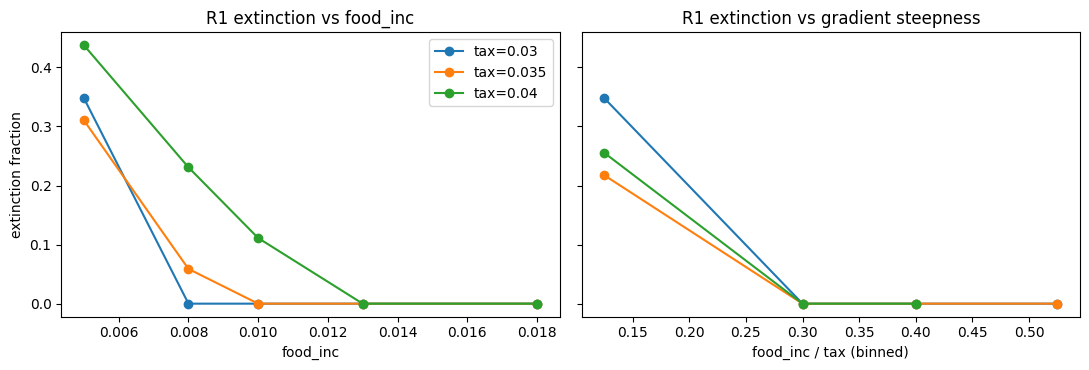

In [6]:
R1['ratio'] = R1.param_food_inc / R1.param_tax
ext_tab = R1.groupby(['param_tax', 'param_food_inc']).extinct.mean().unstack()
print(f"{len(R1)} rows, {int(R1.extinct.sum())} extinct ({R1.extinct.mean():.0%})")
print("extinction fraction by (tax, food_inc), all m_scale pooled:")
display(ext_tab.round(2))

def auc(score, y):   # P(score ranks an extinct run above a viable one), 0.5 = no information
    from scipy.stats import rankdata
    rk = rankdata(score); n1 = y.sum(); n0 = len(y) - n1
    return (rk[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
y = R1.extinct.values.astype(bool)
print(f"AUC for predicting extinction: by -food_inc {auc(-R1.param_food_inc.values, y):.3f}, "
      f"by -food_inc/tax {auc(-R1.ratio.values, y):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for tx, g in R1.groupby('param_tax'):
    e = g.groupby('param_food_inc').extinct.mean()
    ax[0].plot(e.index, e.values, 'o-', label=f'tax={tx:g}')
    gb = g.assign(rb=pd.cut(g.ratio, [0, .25, .35, .45, .6, 1])).groupby('rb', observed=True)
    ax[1].plot([iv.mid for iv in gb.extinct.mean().index], gb.extinct.mean().values, 'o-', label=f'tax={tx:g}')
ax[0].set_xlabel('food_inc'); ax[1].set_xlabel('food_inc / tax (binned)')
ax[0].set_ylabel('extinction fraction'); ax[0].legend(); ax[0].set_title('R1 extinction vs food_inc')
ax[1].set_title('R1 extinction vs gradient steepness')
fig.tight_layout(); plt.show()

**Observation (rescan).** Extinction now sits only at `food_inc` <= 0.010: 35/31/44% at 0.005 for `tax`
0.030/0.035/0.040, 0/6/23% at 0.008, 0/0/11% at 0.010. Ordering extinction by the ratio still does slightly better than
by `food_inc` alone (AUC 0.894 vs 0.872). With `tax` spanning only 33%, this remains a hint, not a collapse test
(ISSUES RES-Q4).

### Example runs: a starved, an intermediate and a rich `food_inc` (with the L1 dissipation probes)

R1 never had a dissipation readout, so everything below is **new, observed in these example runs, not a
campaign result**. Config: R1 row `config_idx=208` of the standard rescan, loaded through the public recipe path
(`evoca_from_scan` then `import_run`; the row records `food_cap=1`): `m_scale` 3.5, `tax` 0.035, `gdiff` 0.08, `mu_lut` 0.03,
`mu_egene` = `mu_egenome` = 0.003, `restricted_mu` on, `tax_per_egene` 0.0008 (at its scanned
`food_inc` 0.018 this row is viable). Only `food_inc` is changed: **0.010 starved**, **0.016
intermediate** (inside R1's productive window), **0.050 rich** (beyond anything R1 sampled). N=128, 3000
steps, seed 0. Plots: alive population; per-capita throughput Phi (= `diss_step / alive`); dissipation
breakdown per step, stacked (tax, death of evicted cells, overflow past the F=1 cap) with mouthful intake
overlaid; and the env-food field (colormode 1) at t=200 and t=3000.

In [7]:
EX = {'starved': 0.010, 'intermediate': 0.016, 'rich': 0.050}
ex_series, ex_shots, ex_resid = {}, {}, {}
t0 = time.time()
for name, fi in EX.items():
    sim, _ = sim_from_scan(R1_SCAN, 208, N=128, seed=0, food_inc=fi)
    ex_series[name], ex_shots[name], ex_resid[name] = trace(sim, 3000, every=25, snaps=(200, 3000))
    sim.free()
print(f"3 example runs in {time.time()-t0:.0f} s")
print("worst whole-system energy-identity residual |source - d(storage) - diss| per run:",
      {k: f'{v:.2e}' for k, v in ex_resid.items()})

3 example runs in 5 s
worst whole-system energy-identity residual |source - d(storage) - diss| per run: {'starved': '2.14e-04', 'intermediate': '4.58e-04', 'rich': '8.54e-04'}


In [8]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim, _ = sim_from_scan(R1_SCAN, 208, N=256, seed=0, food_inc=0.016)   # starved 0.010, intermediate 0.016, rich 0.050
# run_with_controls(sim, cell_px=2, colormode=1, probes={'ts': True})

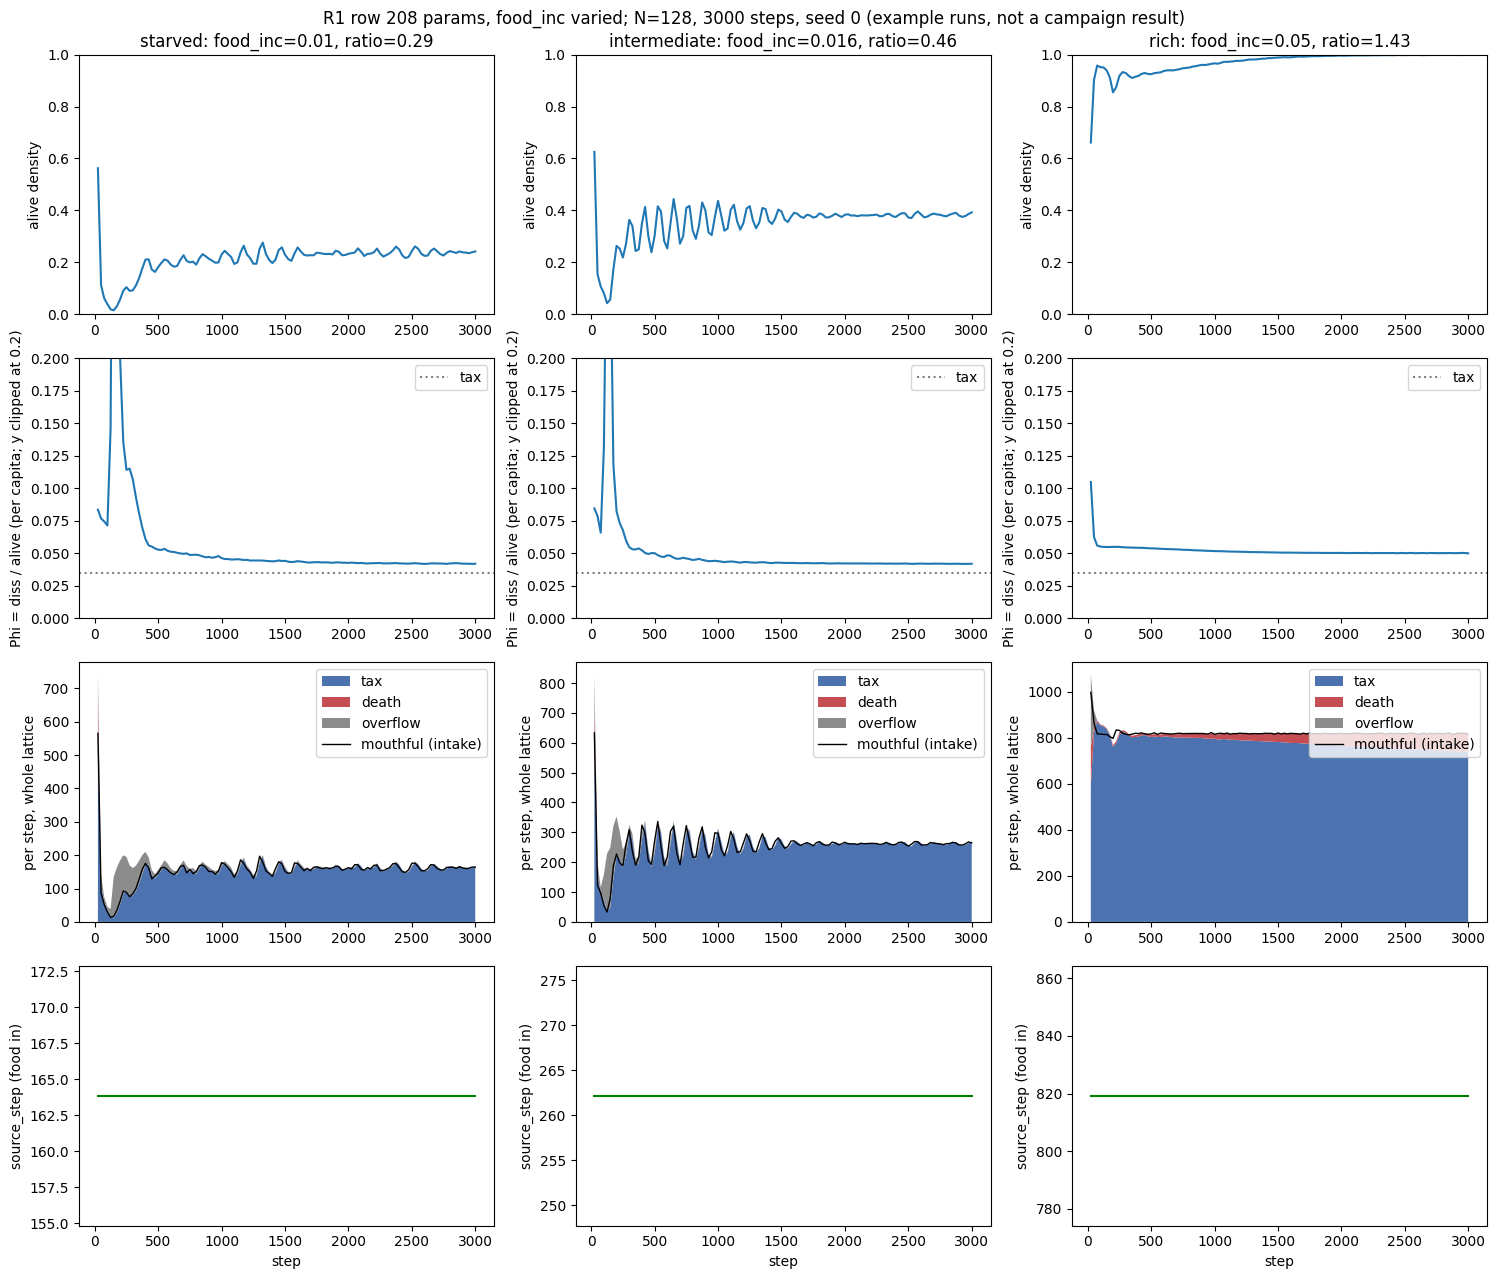

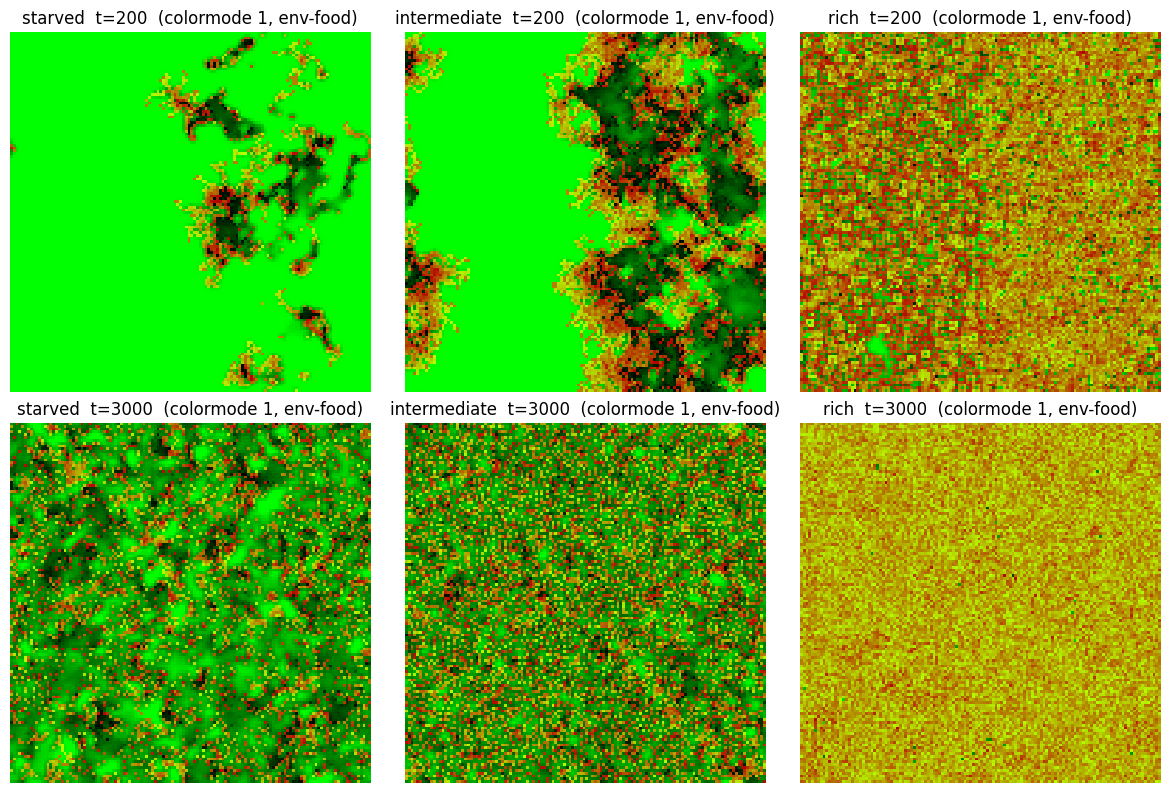

In [9]:
fig, axs = plt.subplots(4, 3, figsize=(15, 13))
for j, (name, fi) in enumerate(EX.items()):
    s = ex_series[name]
    axs[0, j].plot(s.t, s.alive / 128**2); axs[0, j].set_ylim(0, 1)
    axs[0, j].set_title(f'{name}: food_inc={fi}, ratio={fi/0.035:.2f}'); axs[0, j].set_ylabel('alive density')
    axs[1, j].plot(s.t, s.phi); axs[1, j].set_ylim(0, 0.2); axs[1, j].set_ylabel('Phi = diss / alive (per capita; y clipped at 0.2)')
    axs[1, j].axhline(0.035, color='gray', ls=':', label='tax'); axs[1, j].legend(loc='upper right')
    axs[2, j].stackplot(s.t, s.tax, s.death, s.overflow, labels=['tax', 'death', 'overflow'],
                        colors=['#4c72b0', '#c44e52', '#8c8c8c'])
    axs[2, j].plot(s.t, s.mouthful, 'k-', lw=1, label='mouthful (intake)')
    axs[2, j].set_ylabel('per step, whole lattice'); axs[2, j].legend(loc='upper right')
    axs[3, j].plot(s.t, s.source, color='green'); axs[3, j].set_ylabel('source_step (food in)')
    axs[3, j].set_xlabel('step')
fig.suptitle('R1 row 208 params, food_inc varied; N=128, 3000 steps, seed 0 (example runs, not a campaign result)')
fig.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for j, name in enumerate(EX):
    for i, t in enumerate((200, 3000)):
        axs[i, j].imshow(ex_shots[name][t], interpolation='nearest'); axs[i, j].axis('off')
        axs[i, j].set_title(f'{name}  t={t}  (colormode 1, env-food)')
fig.tight_layout(); plt.show()

In [10]:
rows = []
for name, s in ex_series.items():
    late = s[s.t > 2000]
    rows.append(dict(run=name, food_inc=EX[name], ratio=round(EX[name] / 0.035, 2),
                     alive_final=int(s.alive.iloc[-1]), density_final=round(s.alive.iloc[-1] / 128**2, 3),
                     phi_late=round(late.phi.mean(), 4), tax_late=round(late.tax.mean(), 1),
                     death_late=round(late.death.mean(), 1), overflow_late=round(late.overflow.mean(), 1),
                     mouthful_late=round(late.mouthful.mean(), 1),
                     source_late=round(late.source.mean(), 1)))
display(pd.DataFrame(rows).set_index('run'))

,food_inc,ratio,alive_final,density_final,phi_late,tax_late,death_late,overflow_late,mouthful_late,source_late
run,,,,,,,,,,
starved,0.010,0.29,3959,0.242,0.0421,162.3,0.0,1.7,162.4,163.8
intermediate,0.016,0.46,6428,0.392,0.0419,262.1,0.0,0.2,262.1,262.1
rich,0.050,1.43,16365,0.999,0.0501,752.1,66.5,0.0,818.7,819.2


### Sanity check against the rescanned R1 rows

Same recipe path, N=128 and 3000 steps versus the scan's N=256, 8000 steps (so only broad agreement is
expected): row 208 (`food_inc` 0.018) and row 45 (`food_inc` 0.005, `m_scale` 3.5), both from the standard rescan.

In [11]:
chk = []
for idx in (208, 45):
    rec = R1[R1.config_idx == idx].iloc[0]
    sim, _ = sim_from_scan(R1_SCAN, idx, N=128, seed=0)
    for _ in range(3000): sim.step()
    alive = sim.get_dissipation()['alive']
    chk.append(dict(config_idx=idx, food_inc=rec.param_food_inc,
                    rescan_density_N256_8000=round(rec.alive_density_final, 3), rescan_extinct=bool(rec.extinct),
                    here_density_N128_3000=round(alive / 128**2, 3), here_extinct_at_end=(alive == 0)))
    sim.free()
display(pd.DataFrame(chk).set_index('config_idx'))

,food_inc,rescan_density_N256_8000,rescan_extinct,here_density_N128_3000,here_extinct_at_end
config_idx,,,,,
208,0.018,0.435,False,0.426,False
45,0.005,0.005,False,0.000,True


**Observations (OBS-R1, all "observed in these example runs, N=128, seed 0, not a campaign result"):**
see the executed outputs above. The cell below states them from the numbers rather than from memory.

In [12]:
s = ex_series
late = lambda n: s[n][s[n].t > 2000]
print("starved      : final alive =", int(s['starved'].alive.iloc[-1]),
      "| extinct at t =", (int(s['starved'][s['starved'].alive == 0].t.iloc[0]) if (s['starved'].alive == 0).any() else 'never'))
print(f"intermediate : late Phi={late('intermediate').phi.mean():.3f} (tax=0.035), late overflow/step={late('intermediate').overflow.mean():.1f}, "
      f"late tax/step={late('intermediate').tax.mean():.1f}")
print(f"rich         : late Phi={late('rich').phi.mean():.3f}, late overflow/step={late('rich').overflow.mean():.1f}, "
      f"late tax/step={late('rich').tax.mean():.1f}, late alive density={late('rich').alive.mean()/128**2:.3f}")
frac = lambda n: late(n).overflow.mean() / max(late(n).source.mean(), 1e-12)
print(f"fraction of food input lost to overflow (late): intermediate {frac('intermediate'):.2f}, rich {frac('rich'):.2f}")

starved      : final alive = 3959 | extinct at t = never
intermediate : late Phi=0.042 (tax=0.035), late overflow/step=0.2, late tax/step=262.1
rich         : late Phi=0.050, late overflow/step=0.0, late tax/step=752.1, late alive density=0.998
fraction of food input lost to overflow (late): intermediate 0.00, rich 0.00


Reading the executed figures (observed in these example runs, N=128, seed 0, **not a campaign result**; the
colormode-1 legend was not verified from source, so colors are described, not decoded beyond "bright green is
the fully replenished field"):

- **Starved (ratio 0.29) survives.** The population crashes to about 0.02 by t=150, recovers, and settles near
  density 0.24 (late mean 0.238, std 0.011). Late intake (162.4 per step) almost equals the source (163.8); overflow is
  1.7 per step.
- **Intermediate (ratio 0.46) is a damped oscillation, then steady.** After the same early bottleneck the density
  oscillates between roughly 0.25 and 0.45, damps by about t=1500, and sits at 0.38 (late std 0.006). Tax carries
  essentially all the dissipation (262.1 of 262.1 in; overflow 0.2, death 0).
- **Rich (ratio 1.43)** fills the lattice (density 0.999). Intake equals the source (818.7 of 819.2); the sinks are tax
  (752.1) plus death of evicted cells (66.5). Phi settles at 0.0501, i.e. `food_inc`.
- **Phi in the food-limited runs is about 0.042, not the nominal `tax` 0.035.** Row 208 has `tax_per_egene` 0.0008,
  so the tax actually paid per cell exceeds 0.035. Density equals `food_inc / Phi` (0.010/0.0421 = 0.238; 0.016/0.0419
  = 0.382), which is the mass-balance identity with the paid tax in place of the nominal one.
- **Env-food field at t=3000:** the starved run has the most spatial structure (bright replenished patches between
  darker depleted ones), the intermediate run a finer mottled texture, the rich run a near-uniform yellow field.
- **Energy identity:** the whole-system residual |source - d(storage) - diss| stays below 1e-3 per step in
  all three runs (float32 accumulation), so the L1 accountant closes.
- Under the standard rule the triple orders as low, intermediate and full occupancy, all viable; extinction at this
  `m_scale` needs `food_inc` below 0.010 (row 45, `food_inc` 0.005, is extinct here at N=128 and barely viable,
  density 0.005, in the N=256 rescan). The legacy triple (starved extinct, intermediate boom-bust) is in the final section.

In [13]:
# Keep one recipe: the intermediate example (standard rule; the 2026-10-15 recipe without _cap1 records the legacy rule, food_cap: 0), loadable for interactive viewing (ts probe + env-food colormode).
sim, _ = sim_from_scan(R1_SCAN, 208, N=128, seed=0, food_inc=0.016)
rp = export_recipe_once(sim, 'R1cfg208_intermediate_fi0p016_cap1', workstream=WS, probes={'ts': True}, colormode=1)   # reuses an existing copy
sim.free()
print('saved recipe:', Path(rp).relative_to(ROOT), "(load with import_run(<name>, recipe='final'))")

saved recipe: Research/Resource-driving/Runs/2026-10-23_R1cfg208_intermediate_fi0p016_cap1.evoca (load with import_run(<name>, recipe='final'))


In [14]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim, kw = import_run(Path(rp).name, N=256, recipe='final')
# run_with_controls(sim, cell_px=2, **kw)

**Directions from R1** (carried into `ISSUES.md`): widen the `tax` axis well beyond {0.030 to 0.040} and the
`food_inc` axis well above 0.018 so the `food_inc/tax` collapse and the high-resource flank can be tested (R1 never
sampled the rich flank); hold `m_scale` fixed per arm, because under the cap `m_scale` drives `eg_excess` up
monotonically to the grid edge; read productive optima through `A_new`, not just `dyn_excess` (see the next section).

---
## Current state and directions (2026-10)

**Where things stand.**
- The inverted-U is a *prediction* (checkpoint section B/L). Under the standard model R1 gives it little direct
  support: viability is 90%, extinction is confined to `food_inc` <= 0.010, and the composite winners spread over
  `food_inc` 0.005 to 0.018. R1 never sampled the rich flank, so the high-resource half of the U has **not been
  tested** at campaign scale, and the digest `digests/resource-driving-inverted-U.ipynb` is still a skeleton.
- R1's `m_scale` findings did not survive the cap: no U-shaped viability and no interior optimum; `eg_excess` rises
  monotonically with `m_scale` to the grid edge (rescan and `food_cap_impact`, both above).
- The two instruments that blocked the section-B figure are on `main` (merged 2026-10-15): the L1
  dissipation accountant (`sim.get_dissipation()`, and `diss_*` / `diss_phi_*` keys in `run_sim`) and
  `A_new` (G1; `a_new_final`, `a_new_slope` in `run_sim`).
- C1 `food_per` is on `main` (RES-D1); C2/L2 (float `env_mask`, spatial gradient niches) and the C3 campaign are not
  built (ISSUES RES-N5, RES-N6). **Not used here.**

### Pilot: Phi and A_new versus `food_inc/tax` (6 points, N=128, 3000 steps, single seed)

> **PILOT. Not a campaign result.** One seed, one `tax`, N=128, 3000 steps, 6 points. Its purpose is to check
> that the instruments produce a sensible curve and to size the real campaign (spec in `ISSUES.md`, item RES-N1).
> The full design (two or more `tax` levels spanning a wide range, replicate seeds, larger N and longer runs,
> several `m_scale`) is **not** run here.

Config: `build_sim` (GoL LUT, egenome 3, halfplane start) with `m_scale` 3.5, `tax` 0.035, `gdiff` 0.08,
`mu_lut` 0.03, `restricted_mu` on, `food_cap` 1, and **`mu_egene` = `mu_egenome` = 0 (LUT-only evolution)**. The egene
mutations are switched off on purpose: the Channon neutral shadow behind `A_new` models LUT bytes only while
the activity hash covers the full genome, so `A_new` (like `excess_pc`) is not well posed when egenes evolve
(see ISSUES item RES-Q3). `food_inc` = 0.0105, 0.014, 0.021, 0.0315, 0.05, 0.10, i.e. `food_inc/tax` =
0.3, 0.4, 0.6, 0.9, 1.43, 2.86. All columns come from the public `run_sim` (`a_new_*`, `dyn_excess_pc_slope`, `n_distinct_genomes_mean`,
and the `diss_*` keys; the Phi and channel values are means over the run's 31 samples, transient included).

In [15]:
PILOT_FI = [0.0105, 0.014, 0.021, 0.0315, 0.05, 0.10]
PILOT_BASE = dict(m_scale=3.5, tax=0.035, gdiff=0.08, mu_lut=0.03, mu_egene=0.0, mu_egenome=0.0,
                  restricted_mu=True, tax_per_egene=0.0, food_cap=1)
t0 = time.time(); prow = []
for fi in PILOT_FI:
    m = ee.run_sim({**PILOT_BASE, 'food_inc': fi}, n_steps=3000, sample_every=100, N=128, seed=0, shadow=True)
    prow.append(dict(food_inc=fi, ratio=fi / PILOT_BASE['tax'], extinct=m['extinct'],
                     density_final=m['final_pop'] / 128**2, density_pred=min(1.0, fi / PILOT_BASE['tax']),
                     phi_mean=m['diss_phi_mean'], tax_step=m['diss_tax_step_mean'],
                     death_step=m['diss_death_step_mean'], overflow_step=m['diss_overflow_step_mean'],
                     source_step=m['diss_source_step_mean'],
                     a_new_final=m['a_new_final'], a_new_slope=m['a_new_slope'],
                     dyn_excess_pc_slope=m['dyn_excess_pc_slope'], n_distinct_mean=m['n_distinct_genomes_mean']))
P = pd.DataFrame(prow)
print(f"pilot: 6 points in {time.time()-t0:.0f} s")
display(P.round(4).set_index('food_inc'))

pilot: 6 points in 15 s


,ratio,extinct,density_final,density_pred,phi_mean,tax_step,death_step,overflow_step,source_step,a_new_final,a_new_slope,dyn_excess_pc_slope,n_distinct_mean
food_inc,,,,,,,,,,,,,
0.0105,0.3000,False,0.4835,0.3,0.0430,142.8036,4.4230,18.7486,166.4826,139.0,0.0053,4.3280,4090.8710
0.0140,0.4000,False,0.3993,0.4,0.0344,217.7373,1.4563,1.4389,221.9768,910.0,0.2810,18.1034,6167.2581
0.0210,0.6000,False,0.6002,0.6,0.0339,328.1149,0.0000,0.0003,332.9652,1689.0,0.4059,12.8939,9306.8710
0.0315,0.9000,False,0.8990,0.9,0.0339,499.7058,0.3784,0.0000,499.4477,1148.0,0.4639,2.8498,13383.3871
0.0500,1.4286,False,1.0000,1.0,0.0487,554.9396,242.5843,0.0018,792.7742,782.0,-0.0305,0.7355,15844.3871
0.1000,2.8571,False,1.0000,1.0,0.0970,554.9419,963.1456,71.4071,1585.5484,7.0,0.0003,0.9948,15850.7097


In [16]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = ee.build_sim({**PILOT_BASE, 'food_inc': 0.021}, N=256, seed=0)   # any value in PILOT_FI
# run_with_controls(sim, cell_px=2, colormode=1, probes={'ts': True, 'activity': True})

Every column above comes from the public `run_sim` (single source; `phi_mean` and the `*_step` columns are means over
the 31 samples of the run, which include the initial colonization transient). The next cell steps the same
configuration by hand (`build_sim` plus `sim.step()`, as `trace()` does) at the two lowest ratios and sets the final
population against `run_sim`'s. They agree exactly: since the neutral shadow got its own RNG stream (2026-10-15), the
per-sample activity/shadow updates no longer consume the C random stream, so the two entry points are interchangeable
here. (The 2026-10-15 version of this notebook saw 255 cells by hand and 21 inside `run_sim` at ratio 0.3; that was
before the shadow-RNG fix.) The cell after it shows the ratio-0.3 run in 250-step windows.

In [17]:
hand = []
for fi in PILOT_FI[:2]:
    sim = ee.build_sim({**PILOT_BASE, 'food_inc': fi}, N=128, seed=0)
    for _ in range(3000): sim.step()
    hand.append(dict(ratio=round(fi / PILOT_BASE['tax'], 2), final_pop_by_hand=int(sim.get_dissipation()['alive']),
                     final_pop_run_sim=int(P.loc[P.food_inc == fi, 'density_final'].iloc[0] * 128**2)))
    sim.free()
display(pd.DataFrame(hand).set_index('ratio'))

,final_pop_by_hand,final_pop_run_sim
ratio,,
0.3,7922,7922
0.4,6542,6542


In [18]:
sim = ee.build_sim({**PILOT_BASE, 'food_inc': PILOT_FI[0]}, N=128, seed=0)
a = []
for _ in range(3000):
    sim.step(); a.append(sim.get_dissipation()['alive'] / 128**2)
sim.free(); a = np.array(a).reshape(12, 250)
display(pd.DataFrame(dict(window_start=np.arange(0, 3000, 250), mean=a.mean(1), min=a.min(1), max=a.max(1)))
        .round(3).set_index('window_start').T)

window_start,0,250,500,750,1000,1250,1500,1750,2000,2250,2500,2750
mean,0.244,0.249,0.321,0.203,0.294,0.311,0.190,0.321,0.260,0.238,0.324,0.203
min,0.001,0.020,0.016,0.006,0.006,0.007,0.005,0.006,0.006,0.007,0.007,0.006
max,0.834,0.571,0.698,0.703,0.818,0.791,0.811,0.846,0.847,0.819,0.787,0.748


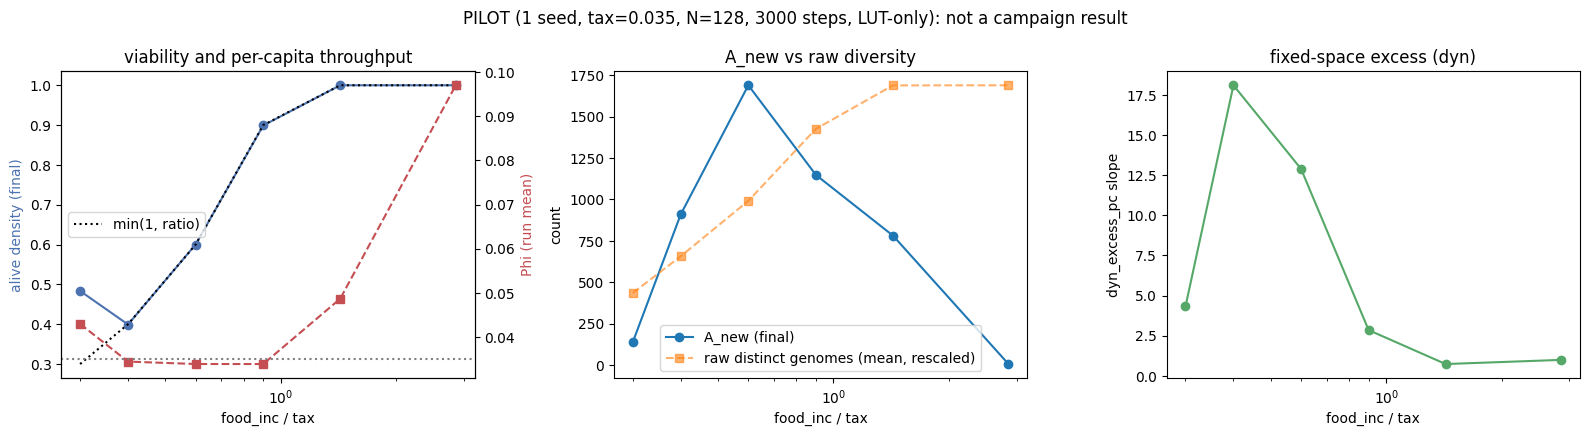

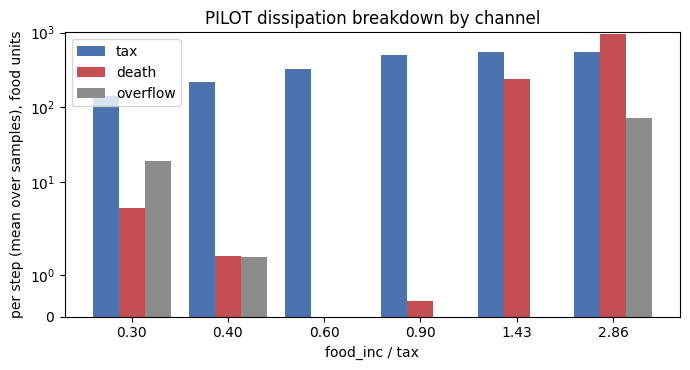

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
x = P.ratio
ax[0].plot(x, P.density_final, 'o-', color='#4c72b0'); ax[0].plot(x, P.density_pred, 'k:', label='min(1, ratio)'); ax[0].legend(loc='center left'); ax[0].set_ylabel('alive density (final)', color='#4c72b0')
a2 = ax[0].twinx(); a2.plot(x, P.phi_mean, 's--', color='#c44e52'); a2.set_ylabel('Phi (run mean)', color='#c44e52')
a2.axhline(PILOT_BASE['tax'], color='gray', ls=':')
ax[0].set_title('viability and per-capita throughput')
ax[1].plot(x, P.a_new_final, 'o-', label='A_new (final)')
ax[1].plot(x, P.n_distinct_mean / P.n_distinct_mean.max() * P.a_new_final.max(), 's--', alpha=.6,
           label='raw distinct genomes (mean, rescaled)')
ax[1].set_ylabel('count'); ax[1].legend(); ax[1].set_title('A_new vs raw diversity')
ax[2].plot(x, P.dyn_excess_pc_slope, 'o-', color='#55a868'); ax[2].set_ylabel('dyn_excess_pc slope')
ax[2].set_title('fixed-space excess (dyn)')
for a in (ax[0], ax[1], ax[2]):
    a.set_xscale('log'); a.set_xlabel('food_inc / tax')
fig.suptitle('PILOT (1 seed, tax=0.035, N=128, 3000 steps, LUT-only): not a campaign result')
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
b = np.arange(len(P)); w = .27
ax.bar(b - w, P.tax_step, w, label='tax', color='#4c72b0'); ax.bar(b, P.death_step, w, label='death', color='#c44e52')
ax.bar(b + w, P.overflow_step, w, label='overflow', color='#8c8c8c')
ax.set_xticks(b); ax.set_xticklabels([f'{r:.2f}' for r in P.ratio]); ax.set_yscale('symlog')
ax.set_xlabel('food_inc / tax'); ax.set_ylabel('per step (mean over samples), food units'); ax.legend()
ax.set_title('PILOT dissipation breakdown by channel'); fig.tight_layout(); plt.show()

**Pilot observations (observed in this pilot, N=128, one seed, not a campaign result).** The next cell prints
the quantitative reading from the executed table so the prose and numbers cannot drift apart.

In [20]:
pk = P.loc[P.a_new_final.idxmax()]; hi = P.iloc[-1]; lo = P.iloc[0]
dk = P.loc[P.dyn_excess_pc_slope.idxmax()]
print(f"A_new peaks at food_inc/tax = {pk.ratio:.2f} (A_new={pk.a_new_final:.0f}); dyn_excess_pc slope peaks at "
      f"{dk.ratio:.2f} ({dk.dyn_excess_pc_slope:.1f}, final population {int(round(dk.density_final*128**2))} cells).")
print(f"richest point (ratio {hi.ratio:.2f}): density {hi.density_final:.2f}, raw distinct genomes {hi.n_distinct_mean:.0f}, A_new {hi.a_new_final:.0f}, Phi {hi.phi_mean:.3f}")
print("final density vs min(1, ratio):", list(zip(P.ratio.round(2), P.density_final.round(3), P.density_pred.round(3))))
print("Phi (run mean) vs max(tax, food_inc):", list(zip(P.phi_mean.round(3), np.maximum(0.035, P.food_inc).round(3))))

A_new peaks at food_inc/tax = 0.60 (A_new=1689); dyn_excess_pc slope peaks at 0.40 (18.1, final population 6542 cells).
richest point (ratio 2.86): density 1.00, raw distinct genomes 15851, A_new 7, Phi 0.097
final density vs min(1, ratio): [(0.3, 0.484, 0.3), (0.4, 0.399, 0.4), (0.6, 0.6, 0.6), (0.9, 0.899, 0.9), (1.43, 1.0, 1.0), (2.86, 1.0, 1.0)]
Phi (run mean) vs max(tax, food_inc): [(0.043, 0.035), (0.034, 0.035), (0.034, 0.035), (0.034, 0.035), (0.049, 0.05), (0.097, 0.1)]


**Reading, and what it does not show** (observed in this pilot, N=128, one seed, not a campaign result).
- **Ratio 0.3 is viable under the standard rule, as a boom-bust.** Its mean density per 250-step window is 0.19-0.32,
  but within each window it swings between a minimum of 0.02 or less and a maximum of 0.57-0.85 (table above). The final density 0.484
  is a snapshot of that cycle, not a steady state. This is the near-threshold regime: the 2026-10-15 legacy pilot went
  nearly extinct here (21 cells).
- **The mass-balance identity.** For ratios 0.4 to 0.9 the final alive density equals `food_inc / tax` (0.399, 0.600,
  0.899 against 0.4, 0.6, 0.9; `tax_per_egene` is 0 here), and above ratio 1 the lattice is full. At quasi-steady state
  food in (`food_inc` per cell) equals tax paid (`tax` per alive cell), so below 1 the ratio *is* the carrying
  occupancy. The rising flank of any activity-vs-ratio curve is therefore confounded with population size, and
  excess/`A_new` must be judged per capita or against a population-matched neutral baseline before calling it adaptive.
- **Phi is nearly degenerate as an x-axis.** Phi = max(`tax`, `food_inc`) at steady state: 0.034 across ratios
  0.4 to 0.9, then 0.049 and 0.097 at the two richest points (0.043 at ratio 0.3, the oscillating run). Phi separates
  only the rich flank, where dissipation is carried first by death of evicted cells (243 per step at ratio 1.43) and
  then also by overflow (71 per step at 2.86). It is an accounting check here, not an independent axis (ISSUES RES-Q2).
- **Raw versus excess (checkpoint section B), first look.** The raw distinct-genome count rises with food input and
  saturates at the full lattice (15851), while `A_new` rises, peaks in the interior (1689 at ratio 0.6) and
  collapses to 7 at ratio 2.86. That is the predicted divergence, in one seed, subject to the occupancy confound.
- The fixed-space `dyn_excess_pc` slope peaks at ratio 0.4 (18.1) and falls to 0.7-1.0 on the full lattice
  (ratios 1.43 and 2.86); it falls faster than `A_new` on the food-limited side (2.8 at ratio 0.9).
- Caveats: one seed and one `tax` (so **no collapse test**), LUT-only evolution (the egene axis, where N's two
  "exception" hypotheses live, is off), N=128 and 3000 steps (activity metrics still growing).

**Unblocked by the 2026-10-15 merges:** the section-B figure (B1) and the Phi x-axis; the adaptive-vs-drift
test H1 can use the lineage return reducer (D2, merged) together with `A_new` on this same sweep.

**Outstanding decisions and directions** are in `ISSUES.md` (shown at the top of this notebook): the evolution arms
(RES-D2), the full campaign spec (RES-N1), the egene-aware `A_new` well-posedness question (RES-Q3), and the `ts` probe
lacking Phi (RES-N4).

---
## Legacy rule (`food_cap=0`): results that depend on it

Everything in this section uses the **legacy uncapped mouthful**, which is not part of the model: a cell's mouthful
was clamped only by its own headroom, so for `m_scale x score > 25` it took more than the site held, drove `F`
negative and drained the next eater's private food (defect A9, fixed 2026-10-15). R1 and every stored output of this
notebook before 2026-10-23 ran under it, and every R1 row has `m_scale` >= 2.5, where the cap binds. Nothing in the main
thread depends on this section. Three parts: (1) R1 as recorded against its standard rescan; (2) the legacy half of
`food_cap_impact`; (3) the example triple under the legacy rule. The intermediate member of the triple (R1 row 208 at
`food_inc` 0.016, recipe `Runs/2026-10-15_R1cfg208_intermediate_fi0p016.evoca`, which records `food_cap: 0`) is the
spiral-wave recipe; that finding lives in the legacy section of
[`Research/Reaction-diffusion/Reaction-diffusion.ipynb`](../Reaction-diffusion/Reaction-diffusion.ipynb), which
concludes that the standard model makes no spirals.

### (1) R1 recorded versus rescanned

In [21]:
R1_REC = pd.read_csv(SCANS / R1_REC_SCAN / 'results.csv')
r1_rec, top20_rec = r1_summary(R1_REC)
display(pd.DataFrame({'recorded (legacy, 2026-05-18)': r1_rec, 'rescan (standard, 2026-10-23)': r1_std}))
cmp = pd.DataFrame({'recorded': R1_REC.groupby('param_m_scale').extinct.mean(),
                    'rescan': R1.groupby('param_m_scale').extinct.mean()}).round(3)
print('extinction fraction by m_scale:'); display(cmp)
print('extinction fraction by (m_scale, food_inc), recorded:')
display(R1_REC.groupby(['param_m_scale', 'param_food_inc']).extinct.mean().unstack().round(2))
for name, df in (('recorded', R1_REC), ('rescan', R1)):
    y = df.extinct.values.astype(bool)
    print(f"{name:8s} AUC for extinction: by -food_inc {auc(-df.param_food_inc.values, y):.3f}, "
          f"by -food_inc/tax {auc(-(df.param_food_inc / df.param_tax).values, y):.3f}")

,"recorded (legacy, 2026-05-18)","rescan (standard, 2026-10-23)"
extinct,107/300 (36%),30/300 (10%)
top20 m_scale,"{2.5: 10, 3.5: 8, 5.0: 2}","{2.5: 2, 3.5: 9, 5.0: 9}"
top20 food_inc,"{0.01: 2, 0.013: 8, 0.018: 10}","{0.005: 1, 0.008: 4, 0.01: 3, 0.013: 7, 0.018: 5}"
top20 mu_lut,"{0.01: 2, 0.03: 6, 0.06: 2, 0.1: 3, 0.15: 7}","{0.01: 8, 0.03: 4, 0.06: 2, 0.1: 2, 0.15: 4}"
top20 tax,"{0.03: 11, 0.035: 8, 0.04: 1}","{0.03: 18, 0.035: 2}"
top-quartile dyn_excess_pc_slope: m_scale,"{2.5: 15, 3.5: 16, 5.0: 18}","{2.5: 20, 3.5: 28, 5.0: 20}"
top-quartile dyn_excess_pc_slope: food_inc,"{0.005: 6, 0.008: 8, 0.01: 5, 0.013: 6, 0.018:...","{0.005: 4, 0.008: 13, 0.01: 12, 0.013: 13, 0.0..."
top-quartile eg_excess_pc_slope: m_scale,"{2.5: 27, 3.5: 18, 5.0: 4}","{2.5: 14, 3.5: 25, 5.0: 29}"
top-quartile eg_excess_pc_slope: food_inc,"{0.008: 1, 0.01: 6, 0.013: 15, 0.018: 27}","{0.005: 4, 0.008: 14, 0.01: 8, 0.013: 12, 0.01..."


extinction fraction by m_scale:


,recorded,rescan
param_m_scale,,
2.5,0.427,0.135
3.5,0.560,0.083
5.0,0.053,0.084


extinction fraction by (m_scale, food_inc), recorded:


param_food_inc,0.005,0.008,0.010,0.013,0.018
param_m_scale,,,,,
2.5,1.00,0.83,0.35,0.09,0.0
3.5,0.92,0.90,0.72,0.32,0.0
5.0,0.11,0.10,0.05,0.00,0.0


recorded AUC for extinction: by -food_inc 0.839, by -food_inc/tax 0.863
rescan   AUC for extinction: by -food_inc 0.872, by -food_inc/tax 0.894


**Recorded versus rescanned.** The composite reproduces R1's recorded top-20 counts exactly (`m_scale` 2.5 x10,
3.5 x8, 5.0 x2; `food_inc` 0.018 x10, 0.013 x8, 0.010 x2; `mu_lut` 0.15 x7), so the comparison is like for like. Under
the cap:
- extinction falls from 107/300 (36%) to 30/300 (10%); by `m_scale` from 42.7/56.0/5.3% to 13.5/8.3/8.4%: the U is
  gone, and with it the recorded mechanism (intake below tax at intermediate `m_scale`);
- the composite `m_scale` optimum moves from the interior (2.5 x10, 3.5 x8, 5.0 x2) to the upper edge (2.5 x2, 3.5 x9,
  5.0 x9), and `eg_excess` top-quartile counts flip from 27/18/4 to 14/25/29;
- the `food_inc` "sub-0.010 closed, no metric winners" claim fails: 5 composite winners now sit at 0.005-0.008;
- the "`mu_lut` optimum shifts high" (top-20 mode 0.15) reverses to mode 0.01;
- the hint that extinction orders by the ratio survives (AUC 0.863 vs 0.839 recorded, 0.894 vs 0.872 rescan).

So R1's headline was produced by A9: legacy runs at `m_scale` 2.5-3.5 overdrew sites and starved under scarcity,
while at 5.0 debt-fed churn depressed `eg_excess` (part 2).

### (2) `food_cap_impact`: both halves

In [22]:
sw = FCI[FCI.group == 'sweep']
print('viable fraction by (food_inc, m_scale), legacy (food_cap=0) / standard (food_cap=1):')
display(sw.groupby(['param_food_cap', 'param_food_inc', 'param_m_scale']).extinct.apply(lambda e: 1 - e.mean())
        .unstack().round(2))
print('eg_excess_pc_slope, mean over seeds:')
display(sw.groupby(['param_food_cap', 'param_food_inc', 'param_m_scale']).eg_excess_pc_slope.mean().unstack().round(1))
print('named configs, means over 4 seeds:')
display(FCI[FCI.group != 'sweep'].groupby(['group', 'param_food_cap'])[['alive_density_mean', 'c_birth_rate', 'c_negF_frac',
        'dyn_excess_pc_slope', 'eg_excess_pc_slope']].mean().round(3))

viable fraction by (food_inc, m_scale), legacy (food_cap=0) / standard (food_cap=1):


param_m_scale                  1.0  1.5   2.0   2.5   3.0  3.5  5.0
param_food_cap param_food_inc                                      
0              0.010           1.0  1.0  0.25  0.00  0.00  1.0  1.0
               0.013           1.0  1.0  0.50  0.25  0.75  1.0  1.0
               0.018           1.0  1.0  1.00  1.00  1.00  1.0  1.0
1              0.010           1.0  1.0  1.00  1.00  1.00  1.0  1.0
               0.013           1.0  1.0  1.00  1.00  1.00  1.0  1.0
               0.018           1.0  1.0  1.00  1.00  1.00  1.0  1.0

eg_excess_pc_slope, mean over seeds:


param_m_scale                   1.0   1.5   2.0   2.5   3.0   3.5   5.0
param_food_cap param_food_inc                                          
0              0.010           29.1  32.9   6.7  -0.5  -0.6  12.9   9.2
               0.013           37.2  42.3  26.7  10.5  18.1  20.7  10.9
               0.018           55.8  61.7  68.1  73.0  74.6  58.1  14.0
1              0.010           29.1  34.8  39.0  41.9  46.2  43.7  76.3
               0.013           37.2  41.8  47.4  54.2  62.6  59.1  94.3
               0.018           55.8  55.6  62.2  73.6  80.9  79.1  95.3

named configs, means over 4 seeds:


alive_density_mean  c_birth_rate  c_negF_frac  \
group   param_food_cap                                                  
lin_3c8 0                            0.378         0.037        0.065   
        1                            0.370         0.022        0.000   
r1_174  0                            0.484         0.003        0.059   
        1                            0.473         0.003        0.000   
r1_225  0                            0.325         0.004        0.054   
        1                            0.348         0.003        0.000   

                        dyn_excess_pc_slope  eg_excess_pc_slope  
group   param_food_cap                                           
lin_3c8 0                             3.764               2.970  
        1                             6.237               2.601  
r1_174  0                            14.143              90.055  
        1                            14.181              93.477  
r1_225  0                            19.764              39.400  
        1                            22.201              42.570

**Both halves (N=128, 4 seeds).** Legacy viability collapses at `m_scale` 2.0-3.0 under scarcity (0-25% viable at
`food_inc` 0.010, 25-75% at 0.013) and recovers at 3.5 and 5.0; capped, every run is viable. Legacy `eg_excess` at
`m_scale` 5.0 is 9.2-14.0 against 76.3-95.3 capped, which is what made 5.0 look unproductive in R1. At `m_scale` <= 1.5
the two rules agree closely (identical at 1.0, where the cap cannot bind). The named configs (R1 rows 174 and 225, the
#3c/#8 regime) keep density and excess within a few units; the #3c/#8 regime's birth rate falls from 0.037 to 0.022 per
cell per step and its `dyn_excess_pc_slope` rises from 3.8 to 6.2. Legacy runs hold `F` < 0 on 5.4-6.5% of sites in
those configs; capped runs on none.

### (3) The example triple under the legacy rule

The same three runs as in the main thread (R1 row 208 parameters, N=128, 3000 steps, seed 0), with `food_cap=0`
passed explicitly, set against the standard-rule runs above.

In [23]:
leg_rows = []
for name, fi in EX.items():
    sim, _ = sim_from_scan(R1_SCAN, 208, N=128, seed=0, food_inc=fi, food_cap=0)
    s_leg, _, _ = trace(sim, 3000, every=25)
    sim.free()
    for rule, s in (('legacy', s_leg), ('standard', ex_series[name])):
        late = s[s.t > 2000]
        leg_rows.append(dict(run=name, rule=rule, alive_final=int(s.alive.iloc[-1]),
                             density_late_mean=round(late.alive.mean() / 128**2, 3),
                             density_late_std=round(late.alive.std() / 128**2, 3), phi_late=round(late.phi.mean(), 4),
                             death_late=round(late.death.mean(), 1), overflow_late=round(late.overflow.mean(), 1)))
display(pd.DataFrame(leg_rows).set_index(['run', 'rule']))

alive_final  density_late_mean  density_late_std  \
run          rule                                                         
starved      legacy              0              0.000             0.000   
             standard         3959              0.238             0.011   
intermediate legacy           4915              0.353             0.084   
             standard         6428              0.382             0.006   
rich         legacy          16347              0.997             0.001   
             standard        16365              0.998             0.001   

                       phi_late  death_late  overflow_late  
run          rule                                           
starved      legacy      0.0000         0.0          163.8  
             standard    0.0421         0.0            1.7  
intermediate legacy      0.0447         2.0            5.6  
             standard    0.0419         0.0            0.2  
rich         legacy      0.0501        73.2            0.0  
             standard    0.0501        66.5            0.0

**The triple under the legacy rule.** The starved run (ratio 0.29) goes extinct (overflow then takes the whole
source, 163.8 per step) where the standard run holds density 0.238; the intermediate run keeps a boom-bust (late std
0.084 against 0.006 capped, late mean 0.353 against 0.382) with a little death and overflow; the rich run is the same
under both rules (density 0.997-0.998, Phi 0.0501). The intermediate legacy run is the spiral recipe
(`Runs/2026-10-15_R1cfg208_intermediate_fi0p016.evoca`, `food_cap: 0`); see the Reaction-diffusion notebook's legacy
section. Its standard-rule counterpart is `Runs/2026-10-23_R1cfg208_intermediate_fi0p016_cap1.evoca`.

In [24]:
print(f"notebook wall time: {time.time()-NB_T0:.0f} s")

notebook wall time: 33 s
